# Set 11 — Semantic segmentation with a U-Net (TrayDataset)

Trains the course's small **U-Net** on the *Tray Food Segmentation* dataset, saves the models for the app, then loads a saved model and visualises its segmentation.

Two models are trained with the same network:

| Model | Task | Classes | Input | Loss |
|---|---|---|---|---|
| `models/unet/tray_food_binary` | food vs. not food (as in the course notebook) | 2 | 128 × 208 | BCE + soft Dice |
| `models/unet/tray_multiclass` | every class, as on the slide (notebook exercise 6) | 43 | 256 × 416 | cross-entropy + soft Dice |

The U-Net, data loading, Dice and training loop live in `forensics_app/tools/unet_common.py`, so the app (Sidebar → Deep Learning → **UNet Segmentation**) uses exactly the same code.

Dataset: unzip `TrayDataset.zip` into `datasets/tray/` (git-ignored).

## 1. Setup

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
import torch

PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(PROJECT_ROOT))
from forensics_app.tools import unet_common as uc

DEVICE = uc.available_device()
ROOT = uc.TRAY_DATASET_DIR
print("torch", torch.__version__, "| device:", DEVICE)
print("dataset:", ROOT)

/Users/daveantonio/Desktop/MAI/2_CV/04_projects/CV-MAI-2026-27-ForensicsApp/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


torch 2.15.0 | device: mps
dataset: /Users/daveantonio/Desktop/MAI/2_CV/04_projects/CV-MAI-2026-27-ForensicsApp/datasets/tray/TrayDataset


## 2. The dataset

Four folders: `XTrain` / `yTrain` (images / masks for training) and `XTest` / `yTest` (test). Each mask stores, for every pixel, the **index of its class** (0 = background, 1 = tray, 2 = cutlery, ... up to 42 food and drink classes).

1241 training pairs, 8 test pairs
Example: 1001a01.jpg <-> 1001a01.png
Image: (256, 416, 3) | Mask: (256, 416) | values in mask: [ 0  1  2  7 18 19 22 27 31 37 41]
Classes present: ['background', 'tray', 'cutlery', 'roastlamb', 'gravy', 'zucchini', 'pumpkin', 'jacketpotato', 'soup', 'custard', 'orangejuice']


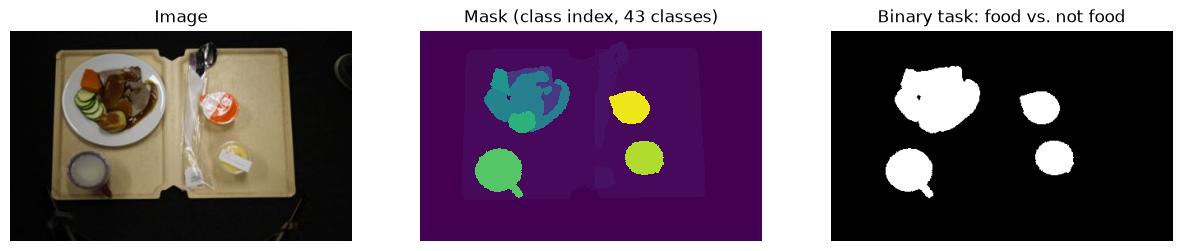

In [2]:
splits = uc.tray_splits(ROOT)
print(f"{len(splits['train'])} training pairs, {len(splits['test'])} test pairs")
img_path, mask_path = splits["train"][0]
print("Example:", img_path.name, "<->", mask_path.name)

img, mask = np.array(Image.open(img_path).convert("RGB")), uc.read_mask(mask_path)
print("Image:", img.shape, "| Mask:", mask.shape, "| values in mask:", np.unique(mask))
print("Classes present:", [uc.CLASS_NAMES[v] for v in np.unique(mask)])

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].imshow(img); ax[0].set_title("Image")
ax[1].imshow(mask, cmap="viridis", vmin=0, vmax=42, interpolation="nearest"); ax[1].set_title("Mask (class index, 43 classes)")
ax[2].imshow(uc.to_task(mask, uc.TASK_BINARY), cmap="gray"); ax[2].set_title("Binary task: food vs. not food")
for a in ax: a.axis("off")
plt.show()

## 3. The U-Net and the Dice coefficient

The encoder (convolutions + max-pooling) learns *what* is in the image, the decoder (transposed convolutions) says *where*, and **skip connections** give back the spatial detail lost by pooling. Three poolings, so height and width must be divisible by 8.

The **Dice coefficient** $\text{Dice}(P, G) = \frac{2|P \cap G|}{|P| + |G|}$ measures overlap: 1 for a perfect match, 0 for none. Unlike pixel accuracy it is not fooled by large backgrounds.

In [3]:
for task in uc.TASKS:
    h, w = uc.TASK_DEFAULTS[task]["size"]
    m = uc.build_unet(out_ch=uc.output_channels(task), base=uc.TASK_DEFAULTS[task]["base"])
    print(f"{task:10s} parameters: {uc.count_parameters(m):,} | output:", tuple(m(torch.zeros(1, 3, h, w)).shape))

P = np.array([[0, 1, 1, 0], [0, 1, 1, 0], [0, 0, 0, 0], [0, 0, 0, 0]])
G = np.array([[0, 0, 1, 1], [0, 0, 1, 1], [0, 0, 0, 0], [0, 0, 0, 0]])
print(f"Dice = {uc.dice_score(P, G):.2f}  vs  pixel accuracy = {(P == G).mean():.2f}  (IoU = {uc.iou_score(P, G):.2f})")

binary     parameters: 482,737 | output: (1, 1, 128, 208)
multiclass parameters: 1,928,395 | output: (1, 43, 256, 416)
Dice = 0.50  vs  pixel accuracy = 0.75  (IoU = 0.33)


## 4. Binary model: food vs. not food (course notebook)

Classes 0–4 (background, tray, cutlery, form, straw) are *not food*, every class from 5 on is *food*. Images are resized to 128 × 208, 15 % of the training images are kept for validation and the epoch with the best validation Dice is kept.

In [4]:
binary = uc.train_unet(ROOT, uc.TASK_BINARY, device=DEVICE, progress=print)

Loading the dataset…


Epoch 1/15 | loss 1.124 | val Dice 0.644 (best 0.644)


Epoch 2/15 | loss 0.800 | val Dice 0.879 (best 0.879)


Epoch 3/15 | loss 0.554 | val Dice 0.908 (best 0.908)


Epoch 4/15 | loss 0.370 | val Dice 0.923 (best 0.923)


Epoch 5/15 | loss 0.258 | val Dice 0.929 (best 0.929)


... (6 outputs left out)

Epoch 12/15 | loss 0.089 | val Dice 0.932 (best 0.955)


Epoch 13/15 | loss 0.086 | val Dice 0.954 (best 0.955)


Epoch 14/15 | loss 0.076 | val Dice 0.960 (best 0.960)


Epoch 15/15 | loss 0.076 | val Dice 0.958 (best 0.960)
Evaluating on the test set…


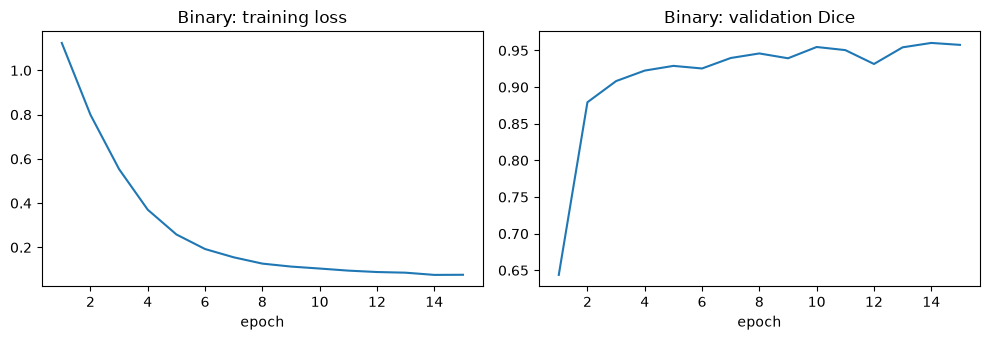

In [5]:
def plot_history(run, title):
    h = run.history
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
    ax[0].plot(range(1, len(h["train_loss"]) + 1), h["train_loss"]); ax[0].set_title(f"{title}: training loss"); ax[0].set_xlabel("epoch")
    ax[1].plot(range(1, len(h["val_score"]) + 1), h["val_score"]); ax[1].set_title(f"{title}: validation {run.passport['metrics']['validation']['score_name']}"); ax[1].set_xlabel("epoch")
    plt.tight_layout(); plt.show()

plot_history(binary, "Binary")

### Evaluation on the test set (Dice, IoU and the threshold of exercise 1)

In [6]:
test = binary.passport["metrics"]["test"]
print(f"Test Dice: {test['dice']:.3f} ± {test['dice_std']:.3f} | IoU: {test['iou']:.3f}  (n = {len(test['per_image_dice'])} images)")
for t in (0.3, 0.5, 0.7):
    r = uc.evaluate(binary.model, binary.test_images, binary.test_labels, uc.TASK_BINARY, DEVICE, threshold=t)
    print(f"threshold {t}: Dice {r['dice']:.3f}, IoU {r['iou']:.3f}")

Test Dice: 0.940 ± 0.032 | IoU: 0.888  (n = 8 images)
threshold 0.3: Dice 0.943, IoU 0.894
threshold 0.5: Dice 0.940, IoU 0.888
threshold 0.7: Dice 0.935, IoU 0.880


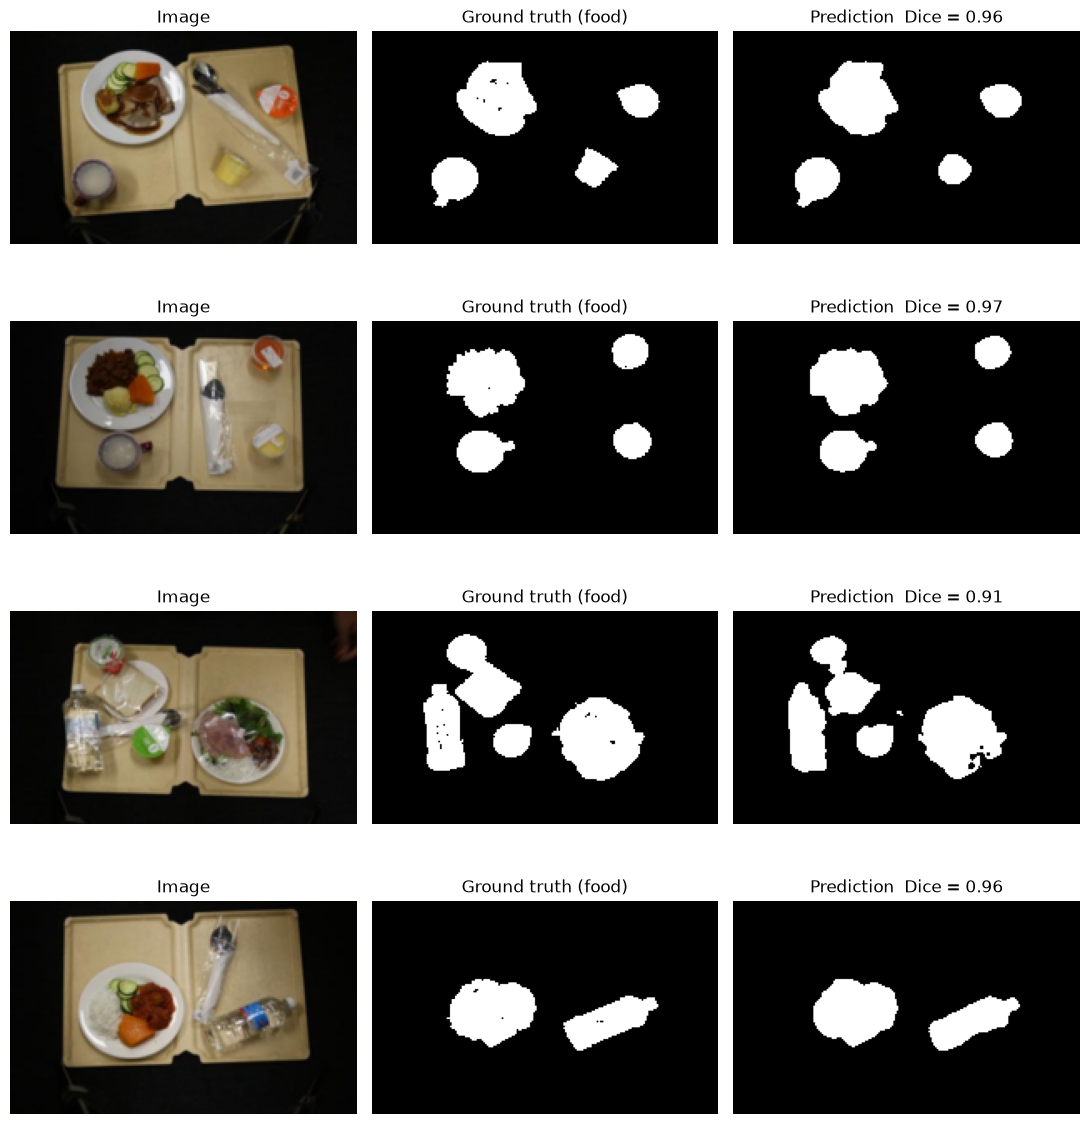

In [7]:
def show_predictions(run, n=4):
    pred = uc.predict_arrays(run.model, run.test_images, run.passport["task"], DEVICE)
    fig, ax = plt.subplots(n, 3, figsize=(11, 3 * n), squeeze=False)
    for r, i in enumerate(range(n)):
        d = uc.dice_score(pred[i], run.test_labels[i])
        ax[r, 0].imshow(run.test_images[i]); ax[r, 0].set_title("Image")
        ax[r, 1].imshow(run.test_labels[i], cmap="gray"); ax[r, 1].set_title("Ground truth (food)")
        ax[r, 2].imshow(pred[i], cmap="gray"); ax[r, 2].set_title(f"Prediction  Dice = {d:.2f}")
        for a in ax[r]: a.axis("off")
    plt.tight_layout(); plt.show()

show_predictions(binary)

In [8]:
uc.save_model(binary.model, binary.passport, uc.UNET_MODELS_DIR / "tray_food_binary")
print("saved to", uc.UNET_MODELS_DIR / "tray_food_binary")

saved to /Users/daveantonio/Desktop/MAI/2_CV/04_projects/CV-MAI-2026-27-ForensicsApp/models/unet/tray_food_binary


## 5. Multi-class model: all 43 classes (slide, notebook exercise 6)

The same U-Net with 43 output channels (one score per class) and twice the width, trained at the full 256 × 416 resolution with cross-entropy + soft Dice. The validation score is the **mean Dice over the classes** that occur in the ground truth.

In [9]:
multi = uc.train_unet(ROOT, uc.TASK_MULTICLASS, device=DEVICE, progress=print)

Loading the dataset…


Epoch 1/30 | loss 2.479 | val mean class Dice 0.142 (best 0.142)


Epoch 2/30 | loss 1.224 | val mean class Dice 0.289 (best 0.289)


Epoch 3/30 | loss 0.917 | val mean class Dice 0.448 (best 0.448)


Epoch 4/30 | loss 0.665 | val mean class Dice 0.639 (best 0.639)


Epoch 5/30 | loss 0.475 | val mean class Dice 0.753 (best 0.753)


... (21 outputs left out)

Epoch 27/30 | loss 0.132 | val mean class Dice 0.946 (best 0.947)


Epoch 28/30 | loss 0.133 | val mean class Dice 0.946 (best 0.947)


Epoch 29/30 | loss 0.133 | val mean class Dice 0.946 (best 0.947)


Epoch 30/30 | loss 0.132 | val mean class Dice 0.947 (best 0.947)
Evaluating on the test set…


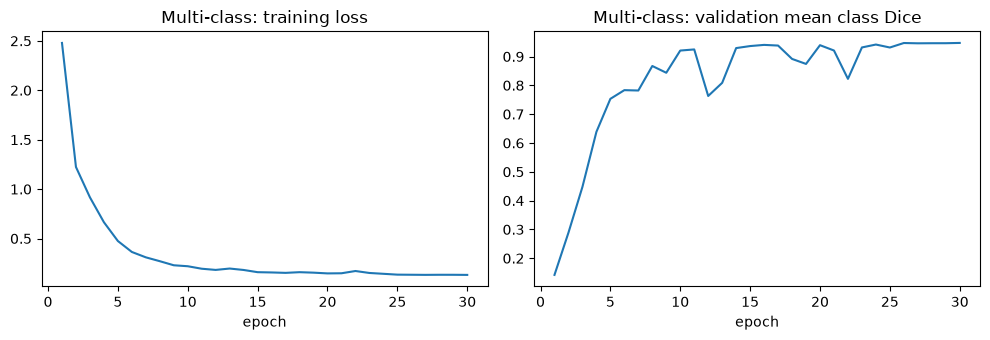

Test mean class Dice: 0.809 | pixel accuracy: 0.971
Food vs. not food Dice from the multi-class predictions: 0.922 (binary model: 0.940)


In [10]:
plot_history(multi, "Multi-class")
test = multi.passport["metrics"]["test"]
print(f"Test mean class Dice: {test['mean_dice']:.3f} | pixel accuracy: {test['pixel_accuracy']:.3f}")
print(f"Food vs. not food Dice from the multi-class predictions: {test['food_dice']:.3f} "
      f"(binary model: {binary.passport['metrics']['test']['dice']:.3f})")

### Dice of each class on the test set (exercise 6)

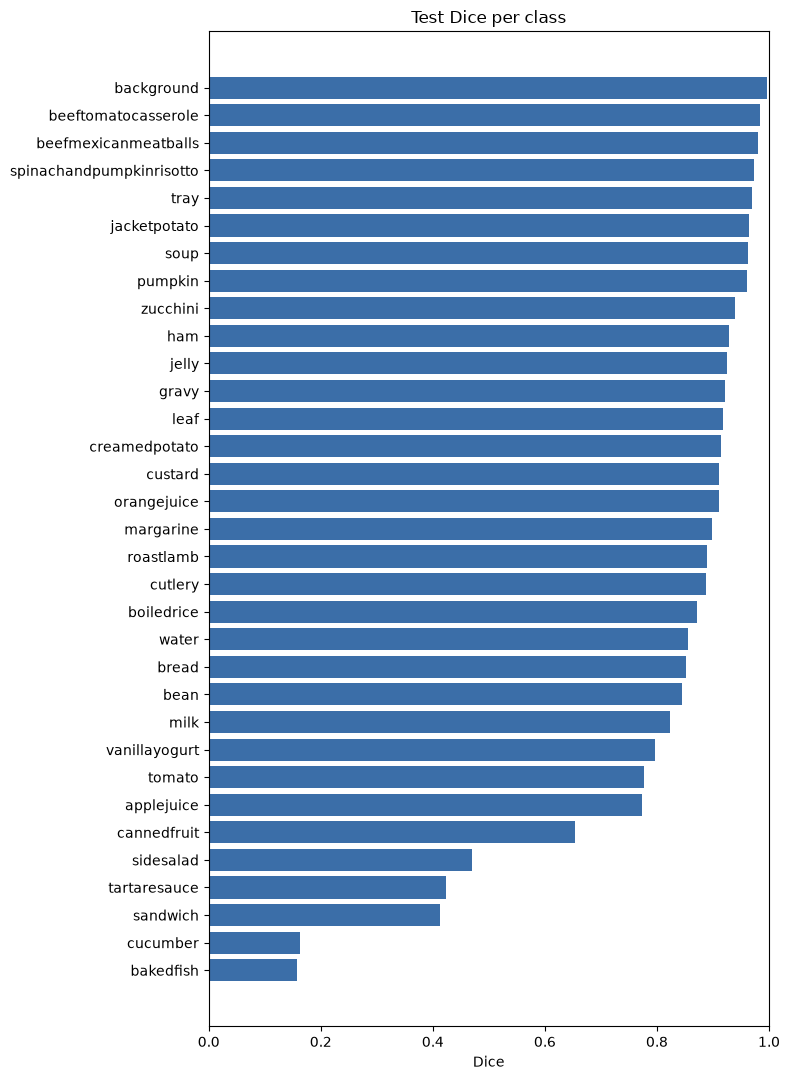

In [11]:
per_class = sorted(test["per_class_dice"].items(), key=lambda kv: kv[1])
plt.figure(figsize=(8, 0.3 * len(per_class) + 1))
plt.barh([k for k, _ in per_class], [v for _, v in per_class], color="#3b6ea8")
plt.xlim(0, 1); plt.xlabel("Dice"); plt.title("Test Dice per class")
plt.tight_layout(); plt.show()

In [12]:
uc.save_model(multi.model, multi.passport, uc.UNET_MODELS_DIR / "tray_multiclass")
print("saved to", uc.UNET_MODELS_DIR / "tray_multiclass")

saved to /Users/daveantonio/Desktop/MAI/2_CV/04_projects/CV-MAI-2026-27-ForensicsApp/models/unet/tray_multiclass


## 6. Load a model and test (visualise the segmentation)

Load the saved models from disk (as the app does) and segment a test image at its original size: original image, segmentation mask and the mask overlaid on the image.

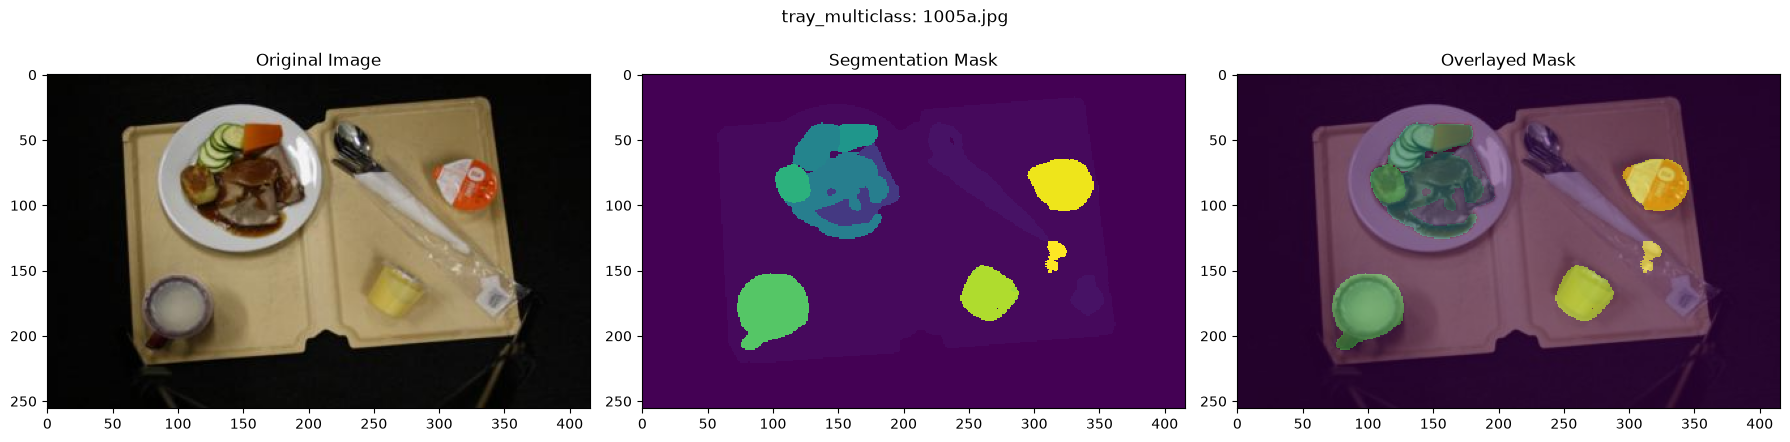

Classes found: background (50%), tray (36%), cutlery (3%), gravy (2%), soup (2%), orangejuice (1%), custard (1%), roastlamb (1%), zucchini (1%), jacketpotato (1%), pumpkin (0%), water (0%), jelly (0%)


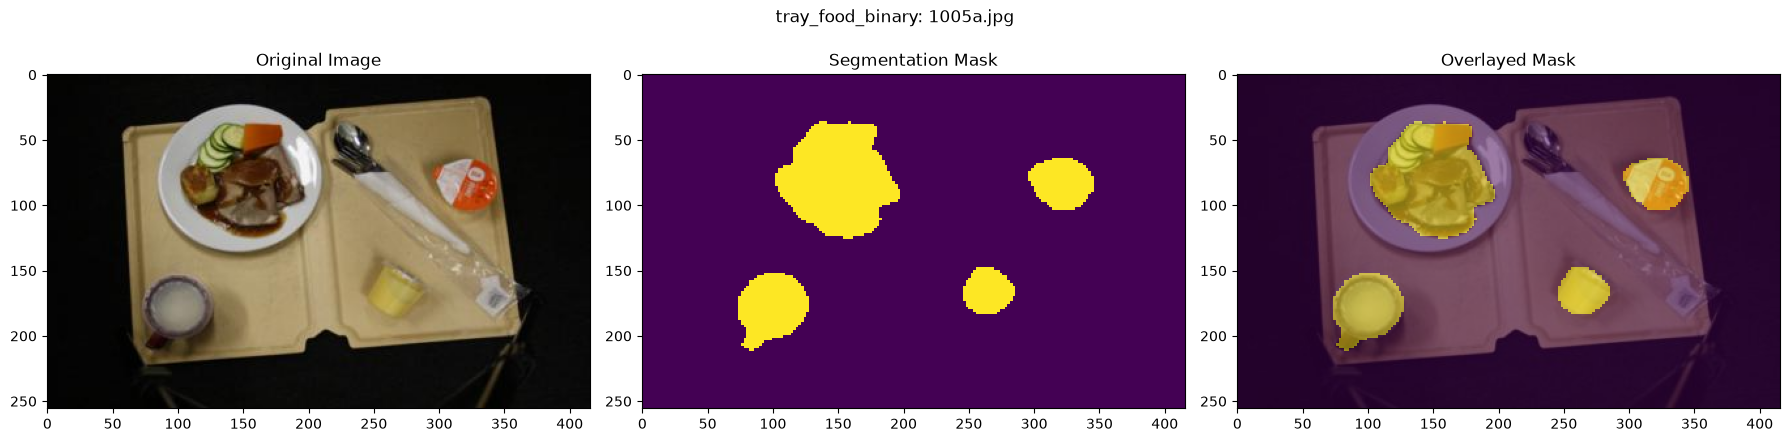

Classes found: not food (90%), food (10%)


In [13]:
def show_segmentation(model_dir, image_path):
    model, passport = uc.load_model(model_dir, DEVICE)
    image = Image.open(image_path).convert("RGB")
    mask = uc.segment(model, passport, image, DEVICE)
    vmax = passport["num_classes"] - 1
    fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
    ax[0].imshow(image); ax[0].set_title("Original Image")
    ax[1].imshow(mask, cmap="viridis", vmin=0, vmax=vmax, interpolation="nearest"); ax[1].set_title("Segmentation Mask")
    ax[2].imshow(image); ax[2].imshow(mask, cmap="viridis", vmin=0, vmax=vmax, alpha=0.5, interpolation="nearest"); ax[2].set_title("Overlayed Mask")
    fig.suptitle(f"{Path(model_dir).name}: {Path(image_path).name}")
    plt.tight_layout(); plt.show()
    print("Classes found:", ", ".join(f"{n} ({f:.0%})" for n, f in uc.label_summary(mask, passport["class_names"])))

test_image = splits["test"][0][0]
show_segmentation(uc.UNET_MODELS_DIR / "tray_multiclass", test_image)
show_segmentation(uc.UNET_MODELS_DIR / "tray_food_binary", test_image)

## 7. Summary

In [14]:
for name, run in (("tray_food_binary", binary), ("tray_multiclass", multi)):
    p = run.passport; t = p["metrics"]["test"]; tr = p["training"]
    score = f"Dice {t['dice']:.3f}" if p["task"] == uc.TASK_BINARY else f"mean class Dice {t['mean_dice']:.3f}, food Dice {t['food_dice']:.3f}"
    print(f"{name:17s} {p['parameters']:>9,} params | {tr['epochs']} epochs (best {tr['best_epoch']}) in {tr['seconds']:.0f}s | test {score}")

tray_food_binary    482,737 params | 15 epochs (best 14) in 41s | test Dice 0.940
tray_multiclass   1,928,395 params | 30 epochs (best 30) in 1152s | test mean class Dice 0.809, food Dice 0.922
